# Final Project 2 — Screw Head Segmentation by Fine-tuning

## Score = 50 (Evaluations 1–3 run) + 100 × test mask mAP@50 + 100 × test mask mAP@50-95 − 10 × log10(parameters in millions, at least 1)

### Opening the test images or labels yourself, or labels downloaded from the original datasets, is cheating → mAP points = 0

Find every screw and name its **head type** — button, flat or pan — with a pretrained model fine-tuned on this data.

**Input** a photograph → **Output** a mask, a class and a score for every screw

Only **50 of the 500 training images are labelled**: label more yourself.

### Terms

- **50** → all three evaluation cells run
- **mask mAP@50**, **mask mAP@50-95** → over the 100 test images
- **Size** → parameters of `model`; 1 M or fewer → 0, 10 M → −10, 100 M → −20
- **Time** → per image; printed, not scored
- **Original datasets** → Roboflow Universe "Screw classification" (project-s0l2s) and MVTec Screws; they publish these photographs with labels
- **Fine-tuning** → pretrained weights from any library, whole model or part

### Tips

- **Tip 1.** Train on the 50 labelled images first, and look at what that model gets wrong
- **Tip 2.** Look for an efficient way to label the 450 unlabelled images
- **Tip 3.** Judge every choice on validation images of your own, never on the test images
- **Tip 4.** Pretrained models come in many sizes; parameters cost points

### Setup and Data

- Data → Roboflow Universe "Screw classification" by project-s0l2s (CC BY 4.0), with photographs of MVTec Screws (CC BY-NC-SA 4.0)
- Training needs a GPU: on Colab the free T4 is enough, and a paid plan offers faster GPUs; make a short run first

In [1]:
import subprocess
import sys

try:
    import torchmetrics
    import pycocotools
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'torchmetrics', 'pycocotools'], check=True)
    import torchmetrics

print(f'torchmetrics {torchmetrics.__version__}')

torchmetrics 1.9.0


In [2]:
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Polygon
from PIL import Image, ImageDraw

np.random.seed(42)
torch.manual_seed(42)

# weights and other files you make go under build/, the dataset under data/
BUILD = Path('build')
DATA = Path('data')
BUILD.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)

print(f'GPU available : {torch.cuda.is_available()}')

GPU available : True


In [3]:
screw_dir = DATA / 'screw_seg'

if not screw_dir.exists():
    urllib.request.urlretrieve('https://raw.githubusercontent.com/jongmoonha/Ajou_ME_AI_Undergraduate/main/data/screw_seg_train.zip', BUILD / 'screw_seg_train.zip')
    urllib.request.urlretrieve('https://raw.githubusercontent.com/jongmoonha/Ajou_ME_AI_Undergraduate/main/data/screw_seg_test.zip', BUILD / 'screw_seg_test.zip')
    # the two archives have no top level folder inside, so the destination folder is named here
    with zipfile.ZipFile(BUILD / 'screw_seg_train.zip') as archive:
        archive.extractall(screw_dir)
    with zipfile.ZipFile(BUILD / 'screw_seg_test.zip') as archive:
        archive.extractall(screw_dir)

labelled_images = sorted((screw_dir / 'labelled' / 'images').glob('*.jpg'))
unlabelled_images = sorted((screw_dir / 'unlabelled' / 'images').glob('*.jpg'))
test_images = sorted((screw_dir / 'test' / 'images').glob('*.jpg'))

print(f'labelled   : {len(labelled_images)} images')
print(f'unlabelled : {len(unlabelled_images)} images')
print(f'test       : {len(test_images)} images')

labelled   : 50 images
unlabelled : 450 images
test       : 100 images


### Labelled, Unlabelled and Test (given)

- `labelled` → 50 training images with labels, `unlabelled` → 450 training images without labels, `test` → for the evaluation cells
- One label file per image, one line per screw: `class x1 y1 x2 y2 ...`, the corners of a polygon as fractions of the image width and height
- `load_instances` → masks and classes of a label file, `evaluate_map` → mAP of `predict` on images with label files; keep both and `test_images` as they are

In [4]:
from torchmetrics.detection import MeanAveragePrecision

class_names = ['button_head', 'flat_head', 'pan_head']      # position = class index in the label files


def load_instances(label_path, size):
    # label file → the screws of an image of that (width, height): masks (N, height, width) bool, class indices (N,)
    lines = label_path.read_text().strip().splitlines()
    masks = np.zeros((len(lines), size[1], size[0]), dtype=bool)
    classes = np.zeros(len(lines), dtype=int)
    for index in range(len(lines)):
        values = lines[index].split()
        corners = np.array([float(value) for value in values[1:]]).reshape(-1, 2)
        corners[:, 0] = corners[:, 0] * size[0]
        corners[:, 1] = corners[:, 1] * size[1]
        mask = Image.new('L', size, 0)
        ImageDraw.Draw(mask).polygon([tuple(corner) for corner in corners], fill=1)
        masks[index] = np.array(mask)
        classes[index] = int(values[0])
    return masks, classes


def evaluate_map(predict, image_paths, label_paths):
    # mask mAP@50 and mAP@50-95 of predict(image) over these images, against their label files
    metric = MeanAveragePrecision(iou_type='segm')
    metric.warn_on_many_detections = False      # no warning past 100 predictions; per image and class the 100 highest scores count
    for image_path, label_path in zip(image_paths, label_paths):
        image = Image.open(image_path)
        masks_pred, classes_pred, scores_pred = predict(image)
        masks_pred = np.asarray(masks_pred)
        classes_pred = np.asarray(classes_pred)
        scores_pred = np.asarray(scores_pred, dtype=float)
        if scores_pred.ndim != 1:
            raise ValueError(f'{image_path.name}: scores must have shape (N,), got {scores_pred.shape}')
        n_found = len(scores_pred)
        if n_found == 0:                        # nothing found in this image
            masks_pred = np.zeros((0, image.height, image.width), dtype=bool)
            classes_pred = np.zeros(0, dtype=int)
        mask_shape = (n_found, image.height, image.width)
        if masks_pred.shape != mask_shape or masks_pred.dtype != bool:
            raise ValueError(f'{image_path.name}: masks have shape {masks_pred.shape} and dtype {masks_pred.dtype}, '
                             f'expected {mask_shape} and bool')
        if classes_pred.shape != (n_found,) or classes_pred.dtype.kind not in 'iu':
            raise ValueError(f'{image_path.name}: classes must be {n_found} integers')
        if classes_pred.min(initial=0) < 0 or classes_pred.max(initial=0) > 2:
            raise ValueError(f'{image_path.name}: classes must be 0, 1 or 2')
        masks_true, classes_true = load_instances(label_path, image.size)
        prediction = {'masks': torch.from_numpy(masks_pred), 'labels': torch.from_numpy(classes_pred).long(),
                      'scores': torch.from_numpy(scores_pred)}
        target = {'masks': torch.from_numpy(masks_true), 'labels': torch.from_numpy(classes_true).long()}
        metric.update([prediction], [target])
    result = metric.compute()
    map50 = max(0.0, result['map_50'].item())       # nothing found in any image → the library gives -1, counted as 0
    map5095 = max(0.0, result['map'].item())        # 'map' is the mean over IoU thresholds 0.50 to 0.95
    return map50, map5095


image = Image.open(labelled_images[0])
masks, classes = load_instances(screw_dir / 'labelled' / 'labels' / (labelled_images[0].stem + '.txt'), image.size)

print(f'image   : size {image.size}, mode {image.mode}')
print(f'masks   : shape {masks.shape}, dtype {masks.dtype}')
print(f'classes : {classes}')

image   : size (800, 600), mode RGB
masks   : shape (8, 600, 800), dtype bool
classes : [1 1 1 1 1 1 1 1]


### Data Exploration

| Class index | Class | Looks like |
|:---|:---|:---|
| 0 | `button_head` | a small rounded dome |
| 1 | `flat_head` | a flat top over a cone |
| 2 | `pan_head` | a wide head that stands above the surface |

- The 50 labelled images hold 14 button, 236 flat and 68 pan head screws
- Nuts and washers are not labelled: leave them out

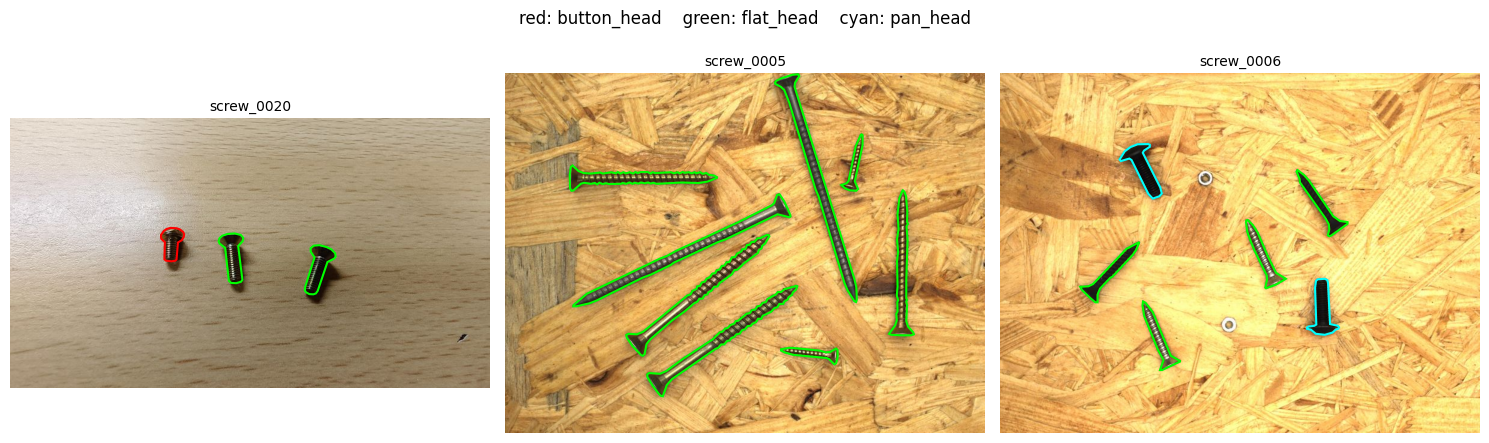

In [5]:
# one labelled image per head type, with the polygons of its label file
class_colors = ['red', 'lime', 'cyan']
class_cmap = ListedColormap(class_colors)
label_paths = sorted((screw_dir / 'labelled' / 'labels').glob('*.txt'))

shown_paths = []
for class_index in range(3):
    for label_path in label_paths:
        classes_here = [int(line.split()[0]) for line in label_path.read_text().strip().splitlines()]
        if class_index in classes_here and label_path not in shown_paths:
            shown_paths.append(label_path)
            break

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for column, label_path in enumerate(shown_paths):
    image = Image.open(screw_dir / 'labelled' / 'images' / (label_path.stem + '.jpg'))
    width, height = image.size

    axes[column].imshow(image)
    for line in label_path.read_text().strip().splitlines():
        values = line.split()
        corners = np.array([float(value) for value in values[1:]]).reshape(-1, 2)
        corners[:, 0] = corners[:, 0] * width
        corners[:, 1] = corners[:, 1] * height
        axes[column].add_patch(Polygon(corners, fill=False, edgecolor=class_colors[int(values[0])], linewidth=1.5))
    axes[column].set_title(label_path.stem, fontsize=10)
    axes[column].axis('off')

fig.suptitle('red: button_head    green: flat_head    cyan: pan_head', fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.95))      # leaves room for the title above the panels
plt.show()

---
## Work Area

### What to Follow

#### 1. Labels

Label any of the 450 unlabelled images, with any tool (model-assisted included), in the format above.

#### 2. Original Datasets

The files given in this notebook are yours to use; **labels downloaded from the two original datasets → mAP points 0.**

#### 3. Other Data

Any other dataset is allowed; list each one in `data_sources`.

#### 4. Model

One `torch.nn.Module` that starts from pretrained weights and is fine-tuned in this notebook.

#### 5. Test Images

**Leave them to the evaluation cells** — opening the test images or labels yourself → mAP points 0.

### What to Define at the End

The evaluation cells need three names:

- `model` — the `torch.nn.Module` you predict with; all its parameters are counted
  - an Ultralytics `YOLO` object → its `.model`
- `data_sources` — list of strings, name and address of each dataset you added; `[]` if none
- `predict` — `predict(image)`: PIL image from disk → three NumPy arrays for the N screws found

| Returned | dtype | Shape | Holds |
|:---|:---|:---|:---|
| `masks` | bool | `(N, image height, image width)` | one mask per screw |
| `classes` | integer | `(N,)` | class index 0–2 |
| `scores` | float | `(N,)` | confidence 0–1, higher is surer |

In [ ]:
# Write your code from here; add cells with [+] as needed.

---
## Evaluation (do not modify)

Run the three cells below as they are; if all three run without an error → 50 points.

- **Evaluation 1** → `predict` on the 100 test images, time per image
- **Evaluation 2** → test mask mAP@50 and mAP@50-95 from `evaluate_map`
- **Evaluation 3** → parameters of `model`, your masks on four test images, your data sources, your score out of 250

In [ ]:
# === Evaluation 1: time per image ===
# Your `predict` must be defined.
import time

time_start = time.perf_counter()
for image_path in test_images:
    image = Image.open(image_path)
    masks_pred, classes_pred, scores_pred = predict(image)
time_end = time.perf_counter()
time_per_image = 1000 * (time_end - time_start) / len(test_images)      # milliseconds, reading the file included

print(f'test images    : {len(test_images)}')
print(f'time per image : {time_per_image:.1f} ms')

In [ ]:
# === Evaluation 2: mask mAP@50 and mAP@50-95 ===
# Your `predict` must be defined.
test_label_paths = []
for image_path in test_images:
    test_label_paths.append(screw_dir / 'test' / 'labels' / (image_path.stem + '.txt'))

map50_test, map5095_test = evaluate_map(predict, test_images, test_label_paths)

print(f'test mask mAP@50    : {map50_test:.4f}')
print(f'test mask mAP@50-95 : {map5095_test:.4f}')

In [ ]:
# === Evaluation 3: model size, pictures, data sources and score ===
# Your `model` and `data_sources` must be defined, and Evaluations 1 and 2 must have run.
n_parameters = sum(p.numel() for p in model.parameters())
n_millions = n_parameters / 1e6

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for column in range(4):
    image = Image.open(test_images[column])
    masks_true, classes_true = load_instances(test_label_paths[column], image.size)
    masks_pred, classes_pred, scores_pred = predict(image)
    masks_pred = np.asarray(masks_pred)

    # painted maps for the two rows: class index + 1 on the pixels of each screw, 0 elsewhere
    painted_true = np.zeros((image.height, image.width), dtype=int)
    for index in range(len(classes_true)):
        painted_true[masks_true[index]] = classes_true[index] + 1
    painted_pred = np.zeros((image.height, image.width), dtype=int)
    for index in range(len(scores_pred)):
        if scores_pred[index] >= 0.5:
            painted_pred[masks_pred[index]] = classes_pred[index] + 1

    axes[0, column].imshow(image)
    axes[0, column].imshow(np.ma.masked_equal(painted_true, 0), cmap=class_cmap, vmin=1, vmax=3, alpha=0.6)
    axes[0, column].set_title(f'{test_images[column].stem}: true masks', fontsize=10)
    axes[1, column].imshow(image)
    axes[1, column].imshow(np.ma.masked_equal(painted_pred, 0), cmap=class_cmap, vmin=1, vmax=3, alpha=0.6)
    axes[1, column].set_title('your masks, score 0.5 or more', fontsize=10)
    for row in range(2):
        axes[row, column].axis('off')

fig.suptitle('red: button_head    green: flat_head    cyan: pan_head', fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.96), h_pad=2.0)      # room for the title above the panels and between the rows
plt.show()

print(f'data sources : {len(data_sources)}')
for source in data_sources:
    print(f'  - {source}')

map50_points = 100 * map50_test
map5095_points = 100 * map5095_test
size_points = 10 * np.log10(max(1.0, n_millions))      # points off: 1 M or fewer → 0, 10 M → 10, 100 M → 20
score = 50 + map50_points + map5095_points - size_points      # 50: this cell printed, so all three evaluation cells ran

print('=' * 88)
print(f'  test mask mAP@50    : {map50_test:.4f}')
print(f'  test mask mAP@50-95 : {map5095_test:.4f}')
print(f'  parameters          : {n_millions:.2f} M')
print(f'  time per image      : {time_per_image:.1f} ms   (not scored)')
print(f'  score               : {score:.1f} / 250   (50 + mAP@50 {map50_points:.1f} + mAP@50-95 {map5095_points:.1f} - size {size_points:.1f})')
print('=' * 88)

---
## Presentation (weeks 15 and 16)

Each student presents both notebooks in about 5 minutes.

1. **Data** → what you labelled or added, and why
2. **Approach** → model and training in each notebook, why
3. **Validation** → what you compared, what moved the score
4. **Test result** → mIoU or mAP, parameters, time
5. **Scratch against fine-tuning** → what differed, and why
6. **Failure cases** → what the predictions get wrong

2 × 250 = 500 points; the presentation is graded separately.

---
## Before You Submit

- Run the notebook top to bottom and keep every output
- Hand in your label files with the notebook
- An error in an evaluation cell → the 50 points are lost
- **Opening the test images or labels yourself, or labels downloaded from the two original datasets → mAP points 0**
- **No pretrained weight in `model`, or a trained weight that `predict` uses outside `model` → mAP points 0**